# Experiment 2
# Production Rules and the Match Phase

In [1]:
# 1. Define production rules

rules = [
    {
        "id": "R1",
        "conditions": ["fever", "cough"],
        "conclusion": "flu"
    },
    {
        "id": "R2",
        "conditions": ["flu"],
        "conclusion": "rest"
    },
    {
        "id": "R3",
        "conditions": ["fever", "rash"],
        "conclusion": "measles"
    },
    {
        "id": "R4",
        "conditions": ["cough", "sore_throat"],
        "conclusion": "cold"
    },
    {
        "id": "R5",
        "conditions": ["flu", "weakness"],
        "conclusion": "doctor_visit"
    }
]

In [2]:
#2. Working Memory
working_memory = {
    "fever",
    "cough"
}

In [7]:
#3. Match Phase

def match_rules(rules, working_memory):

    conflict_set =[]

    for rule in rules:
        #check whether every condition exists in WM
        conditions_satisfied = all(
            condition in working_memory
            for condition in rule["conditions"]
        )

        #Rule matches only if conclusion is not already present
        if conditions_satisfied and rule["conclusion"] not in working_memory:
            conflict_set.append(rule)
    return conflict_set

In [8]:
# 4. Display rules

print("PRODUCTION RULES")
print("=" * 60)

for rule in rules:
    condition_text = " AND ".join(rule["conditions"])

    print(
        f'{rule["id"]}: IF {condition_text} '
        f'THEN {rule["conclusion"]}'
    )

PRODUCTION RULES
R1: IF fever AND cough THEN flu
R2: IF flu THEN rest
R3: IF fever AND rash THEN measles
R4: IF cough AND sore_throat THEN cold
R5: IF flu AND weakness THEN doctor_visit


In [9]:
# 5. Display working memory

print("\nWORKING MEMORY")
print("=" * 60)

print(working_memory)


WORKING MEMORY
{'cough', 'fever'}


In [10]:
# 6. Calculate conflict set

conflict_set = match_rules(rules, working_memory)

In [11]:
# 7. Display conflict set

print("\nCONFLICT SET")
print("=" * 60)

for rule in conflict_set:
    print(rule["id"])


CONFLICT SET
R1


#Exercise 1 — Add Facts One at a Time

In [12]:
# Exercise 1
# Add facts one at a time

working_memory = set()

facts_to_add = [
    "fever",
    "cough",
    "rash",
    "flu",
    "weakness",
    "sore_throat"
]

print("EXERCISE 1: CHANGING WORKING MEMORY")
print("=" * 70)

for fact in facts_to_add:

    working_memory.add(fact)

    conflict_set = match_rules(rules, working_memory)

    print("\nAdded fact:", fact)
    print("Working Memory:", sorted(working_memory))

    if conflict_set:
        print(
            "Conflict Set:",
            [rule["id"] for rule in conflict_set]
        )
    else:
        print("Conflict Set: Empty")

EXERCISE 1: CHANGING WORKING MEMORY

Added fact: fever
Working Memory: ['fever']
Conflict Set: Empty

Added fact: cough
Working Memory: ['cough', 'fever']
Conflict Set: ['R1']

Added fact: rash
Working Memory: ['cough', 'fever', 'rash']
Conflict Set: ['R1', 'R3']

Added fact: flu
Working Memory: ['cough', 'fever', 'flu', 'rash']
Conflict Set: ['R2', 'R3']

Added fact: weakness
Working Memory: ['cough', 'fever', 'flu', 'rash', 'weakness']
Conflict Set: ['R2', 'R3', 'R5']

Added fact: sore_throat
Working Memory: ['cough', 'fever', 'flu', 'rash', 'sore_throat', 'weakness']
Conflict Set: ['R2', 'R3', 'R4', 'R5']


#Exercise 2 - Support NOT fact

In [13]:
# Production rules with NOT conditions

negated_rules = [

    {
        "id": "R1",
        "conditions": ["fever", "cough"],
        "conclusion": "flu"
    },

    {
        "id": "R2",
        "conditions": ["fever", "NOT cough"],
        "conclusion": "unusual_fever"
    },

    {
        "id": "R3",
        "conditions": ["NOT fever", "cough"],
        "conclusion": "possible_cold"
    },

    {
        "id": "R4",
        "conditions": ["NOT fever", "NOT cough"],
        "conclusion": "healthy"
    },

    {
        "id": "R5",
        "conditions": ["rash", "NOT fever"],
        "conclusion": "skin_condition"
    }
]


In [14]:
# Matcher supporting positive and negative conditions

def condition_matches(condition, working_memory):

    # Positive condition
    if not condition.startswith("NOT "):
        return condition in working_memory

    # Negative condition
    fact = condition[4:]

    return fact not in working_memory

In [15]:
# Match rules

def match_rules_with_negation(rules, working_memory):

    conflict_set = []

    for rule in rules:

        all_conditions_satisfied = all(
            condition_matches(condition, working_memory)
            for condition in rule["conditions"]
        )

        if (
            all_conditions_satisfied
            and rule["conclusion"] not in working_memory
        ):
            conflict_set.append(rule)

    return conflict_set

In [16]:
# Test 1

wm1 = {
    "fever"
}

print("TEST 1")
print("=" * 60)

print("Working Memory:", wm1)

conflict_set = match_rules_with_negation(
    negated_rules,
    wm1
)

print(
    "Conflict Set:",
    [rule["id"] for rule in conflict_set]
)

TEST 1
Working Memory: {'fever'}
Conflict Set: ['R2']


In [17]:
# Test 2

wm2 = {
    "cough"
}

print("\nTEST 2")
print("=" * 60)

print("Working Memory:", wm2)

conflict_set = match_rules_with_negation(
    negated_rules,
    wm2
)

print(
    "Conflict Set:",
    [rule["id"] for rule in conflict_set]
)


TEST 2
Working Memory: {'cough'}
Conflict Set: ['R3']


In [18]:
# Test 3

wm3 = set()

print("\nTEST 3")
print("=" * 60)

print("Working Memory:", wm3)

conflict_set = match_rules_with_negation(
    negated_rules,
    wm3
)

print(
    "Conflict Set:",
    [rule["id"] for rule in conflict_set]
)


TEST 3
Working Memory: set()
Conflict Set: ['R4']


#Exercise 3 — Measure Match Time for up to 1,000 Rules

In [19]:
import time
import matplotlib.pyplot as plt

In [20]:
# Generate rules
def generate_rules(number_of_rules):
    generated_rules = []

    for i in range(number_of_rules):
        generated_rules.append({
            "id":f"R{i}",
            "conditions":[
                f"fact{i%50}",
                f"fact{(i+1)%50}"
            ],
            "conclusion":f"result{i}"
        })
    return generated_rules

In [21]:
# Working memory

benchmark_wm = {
    f"fact{i}"
    for i in range(50)
}

In [22]:
# measure matching time

rule_counts = [
    100,
    200,
    300,
    400,
    500,
    600,
    700,
    800,
    900,
    1000
]

times=[]

for count in rule_counts:

    test_rules = generate_rules(count)

    start_time = time.perf_counter()

    conflict_set = match_rules(
        test_rules,
        benchmark_wm
    )

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    times.append(elapsed_time)

    print(
        f"Rules: {count:4d} | "
        f"Match Time: {elapsed_time:.8f} seconds | "
        f"Conflict Set Size: {len(conflict_set)}"
    )


Rules:  100 | Match Time: 0.00006465 seconds | Conflict Set Size: 100
Rules:  200 | Match Time: 0.00017272 seconds | Conflict Set Size: 200
Rules:  300 | Match Time: 0.00020883 seconds | Conflict Set Size: 300
Rules:  400 | Match Time: 0.00026924 seconds | Conflict Set Size: 400
Rules:  500 | Match Time: 0.00034174 seconds | Conflict Set Size: 500
Rules:  600 | Match Time: 0.00042901 seconds | Conflict Set Size: 600
Rules:  700 | Match Time: 0.00090449 seconds | Conflict Set Size: 700
Rules:  800 | Match Time: 0.00055006 seconds | Conflict Set Size: 800
Rules:  900 | Match Time: 0.00063432 seconds | Conflict Set Size: 900
Rules: 1000 | Match Time: 0.00074912 seconds | Conflict Set Size: 1000


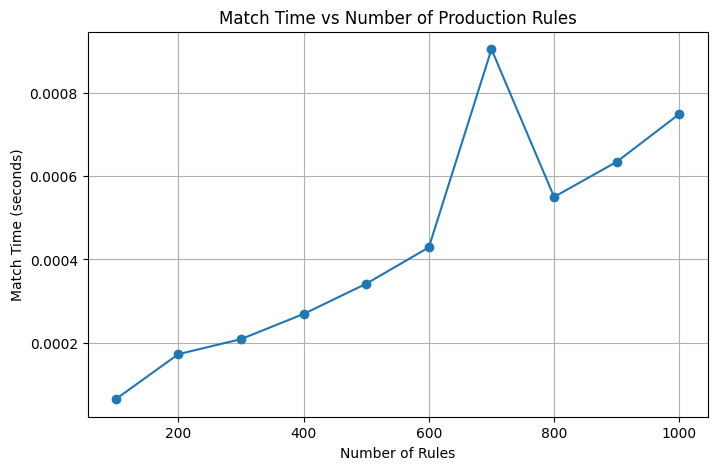

In [23]:
# Plot results

plt.figure(figsize=(8, 5))

plt.plot(
    rule_counts,
    times,
    marker="o"
)

plt.xlabel("Number of Rules")
plt.ylabel("Match Time (seconds)")
plt.title("Match Time vs Number of Production Rules")

plt.grid(True)

plt.show()